In [ ]:
from src.config import SQL_DIR
from src.utils.query import QueryRunner

runner = QueryRunner()

# GOAL

### The purpose of this notebook is to determine which function shape works better as a probability distribution to emulate the characteristics of our real data in our synthetic dataset

#### Query to get the data needed for analysis :

In [ ]:
with open(f"{SQL_DIR}/weibull_query.sql", encoding="utf-8") as f:
    query = f.read()

runner.dry_run_query(query)
result_df = runner.run_query(query)

## Step 1 : Find the best shape

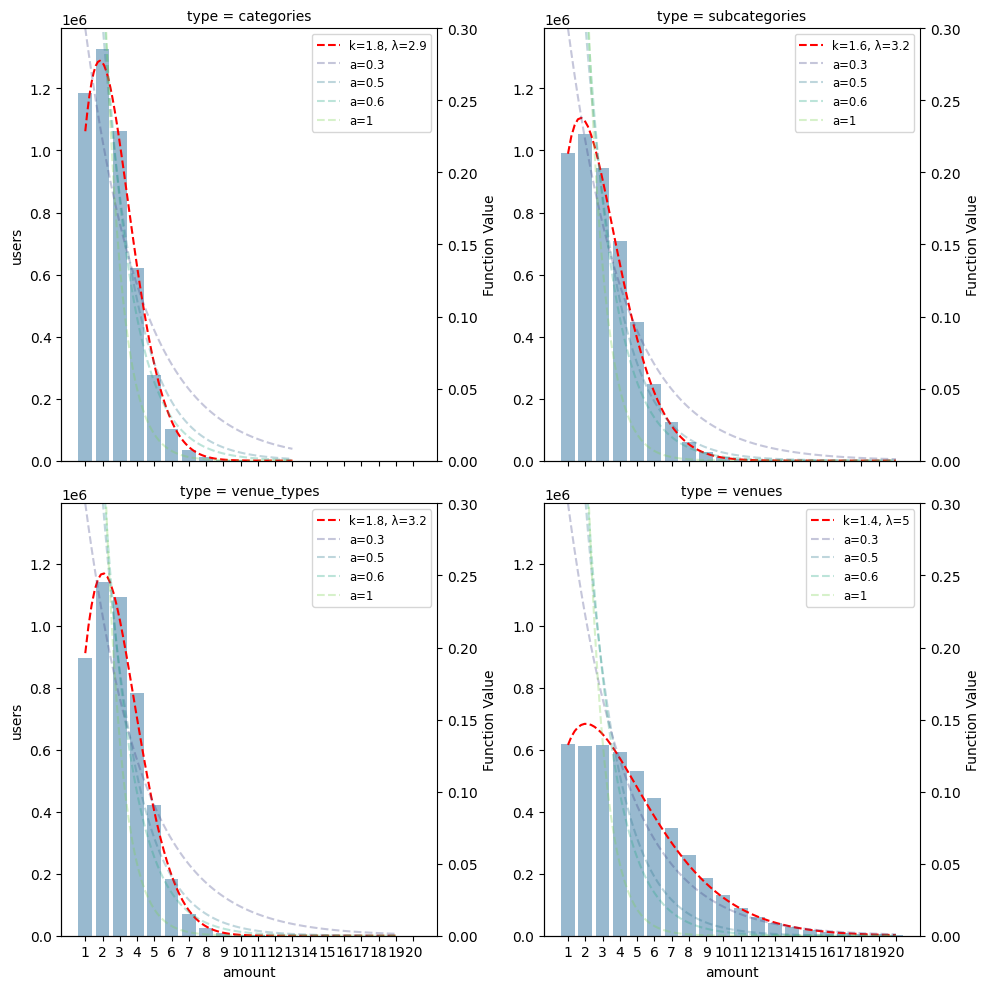

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

params_map = {
    "categories": {"k": 1.8, "lam": 2.9},
    "subcategories": {"k": 1.6, "lam": 3.2},
    "venue_types": {"k": 1.8, "lam": 3.2},
    "venues": {"k": 1.4, "lam": 5},
}

analysis_df = result_df[result_df["amount"] <= 20]


def weibull_decay(x, k=0.5, lam=1.0):
    return (k / lam) * (x / lam) ** (k - 1) * np.exp(-((x / lam) ** k))


def overlay_math_function(data, **kwargs):
    ax = plt.gca()
    current_type = data["type"].iloc[0]

    p = params_map.get(current_type, {"k": 1.0, "lam": 1.0})
    ax2 = ax.twinx()

    x_values = np.sort(data["amount"].unique())
    x_indices = np.linspace(0, len(x_values) - 1, 100)
    x_smooth = np.linspace(1, x_values.max(), 100)
    y_smooth = weibull_decay(x_smooth, k=p["k"], lam=p["lam"])

    ax2.plot(
        x_indices,
        y_smooth,
        label=f"k={p['k']}, λ={p['lam']}",
        color="red",
        linestyle="--",
    )

    a_values = [0.3, 0.5, 0.6, 1]
    colors = sns.color_palette("viridis", len(a_values))

    for a, color in zip(a_values, colors, strict=True):
        y = a * np.exp(-a * x_indices)
        ax2.plot(x_indices, y, label=f"a={a}", color=color, linestyle="--", alpha=0.3)

    ax2.set_ylim(ymin=0, ymax=0.3)
    ax2.set_ylabel("Function Value")
    ax2.legend(fontsize="small")


g = sns.FacetGrid(analysis_df, col="type", col_wrap=2, height=5)
g.map_dataframe(sns.barplot, x="amount", y="users", alpha=0.5)
g.map_dataframe(overlay_math_function)

plt.tight_layout()
plt.show()

We test decreasing exponentials $a \cdot e^{-xa}$ (Poisson distributions of parameter $\frac{1}{a}$ with multiple parameters $a$, but these distributions have issues on the lower end of our scale. <br>
We then test a weibull distribution $$\forall x \geq 0,~ f(x;k, \lambda) = \frac{k}{\lambda} \cdot \left (\frac{x}{\lambda}\right)^{k-1} e^{-\left (\frac{x}{\lambda}\right)^{k}}$$ And we manage to obtain satisfying fits.

## Step 2 : Approximate the distribution

We compare methods to approximate our distribution in our case, and select the best fit

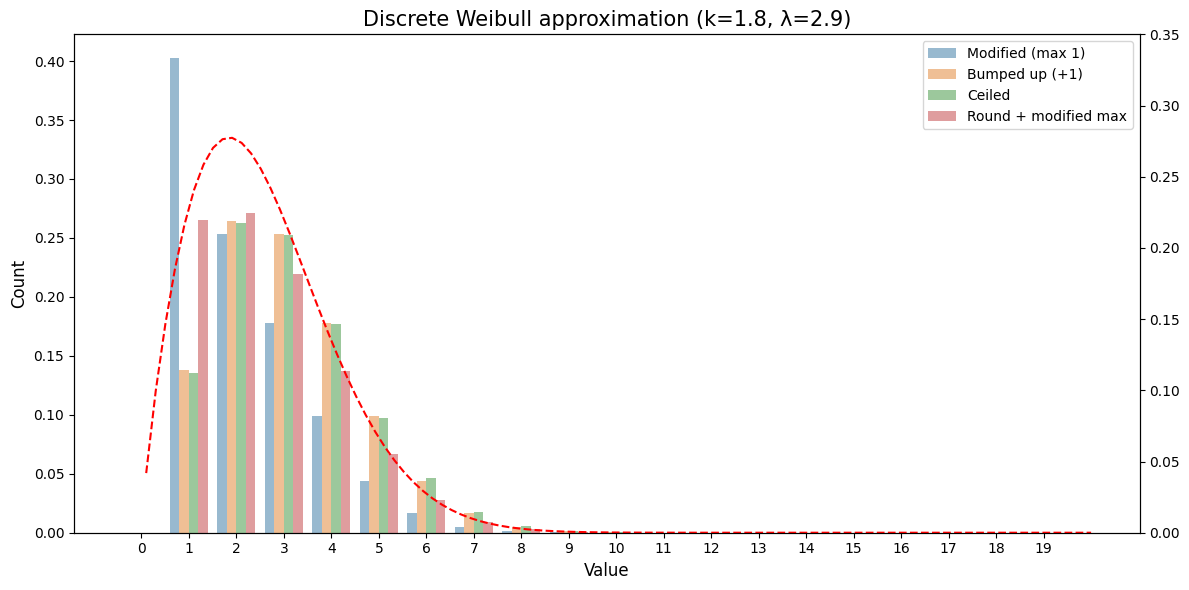

In [4]:
import pandas as pd


def plot_weibull_comparison(k, lam, size=100000):
    _, ax1 = plt.subplots(figsize=(12, 6))

    raw_samples = np.random.weibull(k, size) * lam
    data_orig = raw_samples.astype(int)
    data_round = np.round(raw_samples).astype(int)

    bins = np.arange(0, 20)

    plot_data = []
    for val in bins:
        methods = [
            (np.maximum(1, data_orig), "Modified (max 1)"),
            (data_orig + 1, "Bumped up (+1)"),
            (np.ceil(np.random.weibull(k, size) * lam).astype(int), "Ceiled"),
            (np.maximum(1, data_round), "Round + modified max"),
        ]

        for data, name in methods:
            plot_data.append(
                {"Value": val, "Count": (data == val).sum() / size, "Type": name}
            )

    df = pd.DataFrame(plot_data)

    sns.barplot(data=df, x="Value", y="Count", hue="Type", ax=ax1, alpha=0.5)

    ax2 = ax1.twinx()
    x_smooth = np.linspace(0.1, 20, 100)
    y_smooth = weibull_decay(x_smooth, k, lam)
    ax2.plot(x_smooth, y_smooth, label="Weibull", color="red", linestyle="--")

    ax1.set_title(f"Discrete Weibull approximation (k={k}, λ={lam})", fontsize=15)
    ax1.set_xlabel("Value", fontsize=12)
    ax1.set_ylabel("Count", fontsize=12)
    ax1.legend(loc="upper right")
    ax2.set_ylim(ymin=0, ymax=0.35)

    plt.tight_layout()
    plt.show()


plot_weibull_comparison(k=1.8, lam=2.9)

Best overall fit : ```Round + modified max```

## Step 3 : Validation

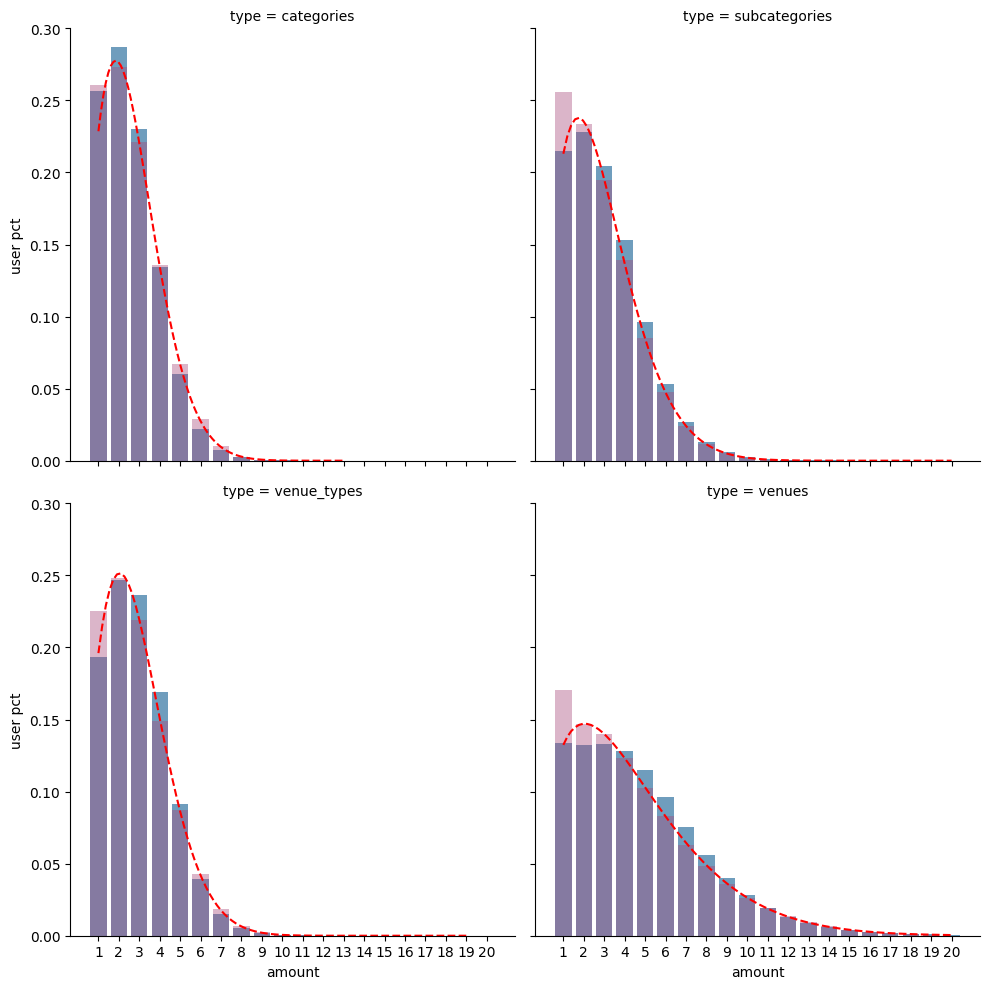

In [ ]:
def overlay_weibull_distribution(data, **kwargs):
    ax = plt.gca()

    current_type = data["type"].iloc[0]
    p = params_map.get(current_type)

    raw_samples = np.random.weibull(p["k"], 100000) * p["lam"]
    data_round = np.round(raw_samples).astype(int)

    bins = np.arange(1, 20)

    plot_data = []
    for val in bins:
        plot_data.append(
            {
                "Value": val,
                "Count": (np.maximum(1, data_round) == val).sum() / 100000,
                "Type": "Round + modified max",
            }
        )

    df = pd.DataFrame(plot_data)

    sns.barplot(
        data=df, x="Value", y="Count", hue="Type", ax=ax, alpha=0.4, palette="magma"
    )

    x_values = np.sort(data["amount"].unique())
    x_indices = np.linspace(0, len(x_values) - 1, 100)
    x_smooth = np.linspace(1, x_values.max(), 100)
    y_smooth = weibull_decay(x_smooth, k=p["k"], lam=p["lam"])

    ax.plot(
        x_indices,
        y_smooth,
        label=f"k={p['k']}, λ={p['lam']}",
        color="red",
        linestyle="--",
    )

    ax.set_ylim(ymin=0, ymax=0.3)
    ax.set_ylabel("user pct")
    ax.legend(fontsize="small")


final_df = analysis_df.copy()
final_df["users"] = final_df["users"] * 4 / final_df["users"].sum()
g = sns.FacetGrid(final_df, col="type", col_wrap=2, height=5)
g.map_dataframe(sns.barplot, x="amount", y="users", alpha=0.7)
g.map_dataframe(overlay_weibull_distribution)

plt.tight_layout()
plt.show()